[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/google-deepmind/hybrid_rnns_reward_learning/blob/main/hybrid_rnns_reward_learning/replicate_paper_fits.ipynb)

# Fit Models: RL-ANN, Context-ANN, Memory-ANN, and Vanilla RNN
This notebook fits and compares the 4 core neural models from the paper "Hybrid neural–cognitive models reveal how memory shapes human reward learning" (Eckstein et al., 2026) on the open-source human behavioral dataset (`openSourceHumDataset.csv` on OSF):
1. **RL-ANN** (`BiRNN`: ANN version of a dual value / habit model, generalizing typical Q-learning models with a separate reward-independent action-repetitoin mechanism; no recurrent state, no output feedback, 16 units, batch size 32)
2. **Context-ANN** (`BiRNN`: output feedback $o=\text{True}$, 64 units, batch size 64)
3. **Memory-ANN** (`BiRNN`: state feedback $s=\text{True}$, value input is zeroed-out, 32 units, batch size 128)
4. **Vanilla RNN** (`RNN`: standard recurrent state $s=\text{True}$, 64 units, batch size 64)

### This notebook implements the following steps:
1. **Model Repository**: Installs [`hybrid_rnns_reward_learning`](https://github.com/google-deepmind/hybrid_rnns_reward_learning) from GitHub.
2. **Data & Splits**: Downloads `openSourceHumDataset.csv` from OSF and partitions blocks using the same assignment as the original paper (`open_source_mapping.csv` from OSF).
3. **Model Fitting**: Sets up config files for each of the 4 models, and fits them.
4. **Evaluation & Comparison**: Calculates held-out test prediction accuracy and plots the results.

In [ ]:
# ── Install hybrid_rnns_reward_learning from GitHub ─────────────────
# Installs the model repository and dependencies (dm-haiku, optax, ml_collections)
!pip install -q git+https://github.com/google-deepmind/hybrid_rnns_reward_learning.git

In [ ]:
# ── Imports ───────────────────────────────────────────────────────────────────
import os
import urllib.request
import haiku as hk
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import pandas as pd

from hybrid_rnns_reward_learning import rnn_config as rc
from hybrid_rnns_reward_learning import hyb_rnn_utilities as util
from hybrid_rnns_reward_learning.bi_rnn import BiRNN
from hybrid_rnns_reward_learning.rnn import RNN
from hybrid_rnns_reward_learning.cogmod import CogMod

print("Successfully imported model functions (BiRNN, RNN, CogMod) from hybrid_rnns_reward_learning.")

Successfully imported model functions (BiRNN, RNN, CogMod) from hybrid_rnns_reward_learning.


# 1. Download Human Data and Split Assignment from OSF
Download the human behavioral dataset from the OSF repository (`https://osf.io/8xz3w/files/sa62j`) into DataFrame `osf_data`. Download the split assignment file from OSF (`https://osf.io/download/azkm8`) into DataFrame `mapping_df`.

In [ ]:
import os
import requests
import pandas as pd

def download_file(url, target_path):
    print(f"Downloading from {url} to {target_path}...")
    # requests automatically handles cert bundles and redirects properly
    # verify=False guarantees it won't fail on macOS SSL issues
    response = requests.get(url, allow_redirects=True, verify=False)
    response.raise_for_status()
    with open(target_path, 'wb') as f:
        f.write(response.content)
    print(f"Successfully downloaded {target_path} ({os.path.getsize(target_path):,} bytes).")

# 1. Download & load the OSF human data
osf_download_url = 'https://osf.io/download/sa62j/'
local_dataset_path = 'openSourceHumDataset.csv'
download_file(osf_download_url, local_dataset_path)

osf_data = pd.read_csv(local_dataset_path)
print(f"Loaded osf_data with shape: {osf_data.shape[0]:,} rows x {osf_data.shape[1]} columns")
print(f"Unique participants (s_id): {osf_data['s_id'].nunique()}")
print(f"Columns: {osf_data.columns.tolist()}")
print(f"\nFirst 3 rows:\n{osf_data.head(3)}")

# 2. Download split mapping from OSF
mapping_download_url = 'https://osf.io/download/azkm8/'
local_mapping_path = 'open_source_mapping.csv'
download_file(mapping_download_url, local_mapping_path)

mapping_df = pd.read_csv(local_mapping_path)
print(f"Loaded mapping_df with shape: {mapping_df.shape[0]:,} rows x {mapping_df.shape[1]} columns")
print(f"Columns: {mapping_df.columns.tolist()}")
print(f"\nFirst 3 rows:\n{mapping_df.head(3)}")


/Users/mariaeckstein/colab-env/lib/python3.15/site-packages/urllib3/connectionpool.py:1129: InsecureRequestWarning: Unverified HTTPS request is being made to host 'osf.io'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/mariaeckstein/colab-env/lib/python3.15/site-packages/urllib3/connectionpool.py:1129: InsecureRequestWarning: Unverified HTTPS request is being made to host 'files.osf.io'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/mariaeckstein/colab-env/lib/python3.15/site-packages/urllib3/connectionpool.py:1129: InsecureRequestWarning: Unverified HTTPS request is being made to host 'idvyorynw6xy.compat.objectstorage.us-ashburn-1.oraclecloud.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tl

Successfully downloaded openSourceHumDataset.csv (45,895,584 bytes).


/var/folders/wc/vpr0lfrj04d4wb7198b0009c00nmr3/T/ipykernel_25957/1284039459.py:20: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  osf_data = pd.read_csv(local_dataset_path)


Loaded osf_data with shape: 623,700 rows x 15 columns
Unique participants (s_id): 862
Columns: ['Age', 'Sex', 'Ethnicity simplified', 'Time taken', 'block', 'trial_id', 'action', 'reward', 'rt', 'missed', 'payout_0', 'payout_1', 'payout_2', 'payout_3', 's_id']

First 3 rows:
  Age     Sex Ethnicity simplified  Time taken  block  trial_id  action  \
0  29  Female                White      1443.0    1.0         0     0.0   
1  29  Female                White      1443.0    1.0         1     2.0   
2  29  Female                White      1443.0    1.0         2     1.0   

   reward     rt  missed  payout_0  payout_1  payout_2  payout_3  s_id  
0    75.0  379.0   False      75.0      97.0      26.0      59.0   268  
1    28.0  212.0   False      74.0      99.0      28.0      53.0   268  
2    93.0  128.0   False      72.0      93.0      34.0      49.0   268  


/Users/mariaeckstein/colab-env/lib/python3.15/site-packages/urllib3/connectionpool.py:1129: InsecureRequestWarning: Unverified HTTPS request is being made to host 'osf.io'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/mariaeckstein/colab-env/lib/python3.15/site-packages/urllib3/connectionpool.py:1129: InsecureRequestWarning: Unverified HTTPS request is being made to host 'files.osf.io'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/mariaeckstein/colab-env/lib/python3.15/site-packages/urllib3/connectionpool.py:1129: InsecureRequestWarning: Unverified HTTPS request is being made to host 'idvyorynw6xy.compat.objectstorage.us-ashburn-1.oraclecloud.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tl

Successfully downloaded open_source_mapping.csv (48,699 bytes).
Loaded mapping_df with shape: 4,134 rows x 3 columns
Columns: ['osf_s_id', 'osf_block', 'split']

First 3 rows:
   osf_s_id  osf_block split
0       268          1  test
1       268          2  test
2       268          3  test


# 2. Preprocess data for model fitting
Exclude blocks with too many missed trials and split the dataset into train, validation, and test using the same splits as the NHB 2026 paper.

This preprocessing:
1. Merges `osf_data` on `(s_id, block)` with the split mapping.
2. Excludes participant blocks with $>15/150$ missed trials (`action == -1` or `NaN`).
3. One-hot encodes actions across 4 choices.
4. Normalizes rewards to `[0, 1]` (`reward / 100.0`).
5. Generates 3D tensors `(n_blocks, 150, 5)` for training, validation, and testing sets.

In [ ]:
# ── 2. Split osf_data into train, valid, and test ─────────────────────────────
# Pre-computed mapping file (open_source_mapping.csv)
def format_data_for_model_training(hum_dat, mapping_df):
  """Format OSF data using the pre-computed split mapping."""
  hum_dat = hum_dat.copy()
  hum_dat['s_id'] = hum_dat['s_id'].astype(int)
  hum_dat['block'] = hum_dat['block'].astype(int)

  mapping_df = mapping_df.copy()
  s_col = 'osf_s_id' if 'osf_s_id' in mapping_df.columns else 's_id'
  b_col = 'osf_block' if 'osf_block' in mapping_df.columns else 'block'

  mapping_df[s_col] = mapping_df[s_col].astype(int)
  mapping_df[b_col] = mapping_df[b_col].astype(int)

  # Inner join assigns split label and automatically excludes blocks with >15 missed trials
  mapping_slim = mapping_df[[s_col, b_col, 'split']].rename(
      columns={s_col: 's_id', b_col: 'block'})
  hum_dat = hum_dat.merge(mapping_slim, on=['s_id', 'block'], how='inner')

  n_trials = len(np.unique(hum_dat['trial_id']))

  # One-hot encoding of actions (missed trials filled with -1 produce all-zeros)
  hum_dat[['choice_0', 'choice_1', 'choice_2', 'choice_3']] = jax.nn.one_hot(
      np.array(hum_dat['action'].fillna(-1).astype(int)), 4)
  hum_dat['reward'] = hum_dat['reward'] / 100.0  # normalize reward to [0, 1]
  necessary_cols = ['choice_0', 'choice_1', 'choice_2', 'choice_3', 'reward']

  def _to_tensor(split_label):
    sub = hum_dat[hum_dat['split'] == split_label][necessary_cols]
    n_blocks = len(sub) // n_trials
    return jnp.array(sub.values).reshape([n_blocks, n_trials, len(necessary_cols)])

  return {
      'train_dat': _to_tensor('train'),
      'valid_dat': _to_tensor('valid'),
      'test_dat':  _to_tensor('test'),
  }

# Format data into train, valid, and test splits
hum_dat_tensor = format_data_for_model_training(osf_data, mapping_df)

train_dat = hum_dat_tensor['train_dat']
valid_dat = hum_dat_tensor['valid_dat']
test_dat = hum_dat_tensor['test_dat']

print(f"\nSplit tensor shapes (n_blocks, n_trials, n_features):")
print(f"  train_dat: {train_dat.shape}")
print(f"  valid_dat: {valid_dat.shape}")
print(f"  test_dat:  {test_dat.shape}")


Split tensor shapes (n_blocks, n_trials, n_features):
  train_dat: (3302, 150, 5)
  valid_dat: (419, 150, 5)
  test_dat:  (413, 150, 5)


# 3. Model Fitting & Evaluation
Next comes the shared training engine and evaluation functions used by all models:
* Cross-entropy NLL loss function (trials with missed responses contribute 0 to the loss).
* Optax AdamW optimizer (`learning_rate=1e-4`, `weight_decay=1e-5`).
* Periodic evaluation on validation data during training.
* Participant-level NLL evaluation on held-out test blocks.
* Conversion of test NLL into normalized likelihood / prediction accuracy percentage:
  $$\text{Prediction %} = 100 \times \exp\left(-\frac{\text{Block NLL}}{150}\right)$$

In [ ]:
# ── Shared Training & Evaluation Engine ────────────────────────────────────────
all_model_results = {}
DEFAULT_N_STEPS = 1000000  # Adjust as needed (paper uses 1,000,000 for most models)

def get_batch(tensor_dat, batch_size, key):
  """Get a random batch of participant blocks."""
  rnd_idxs = jax.random.choice(
      key=key, a=jnp.arange(len(tensor_dat)), shape=(batch_size,), replace=False
  )
  return tensor_dat[rnd_idxs]

def loss_per_participant(forward_fn, model_params, key, action_seq, reward_seq):
  """Cross-entropy loss per participant block, summed across trials and action choices."""
  input_seq = jnp.concatenate([action_seq, reward_seq], axis=-1)
  action_probs_seq, _ = forward_fn.apply(model_params, key, input_seq)
  action_probs_seq = (1.0 - 1e-5) * action_probs_seq + 5e-4
  ce_loss_per_block = -jnp.sum(
      jnp.log(action_probs_seq[:, :-1]) * action_seq[:, 1:],
      axis=[1, 2],
  )
  return np.array(ce_loss_per_block)

def loss_to_percent_predicted(loss, n_trials=150):
  """Converts NLL into prediction percentage (geometric mean probability * 100)."""
  return 100.0 * np.exp(-loss / n_trials)

def make_birnn_forward(cfg):
  """Factory creating a Haiku forward function for BiRNN architectures."""
  def _birnn_fn(input_seq, return_all_states=False):
    bi_rnn = BiRNN(cfg.rnn_rl_params, cfg.network_params)
    initial_state = bi_rnn.initial_state(input_seq.shape[0])
    return hk.dynamic_unroll(
        bi_rnn,
        input_seq,
        initial_state,
        time_major=False,
        return_all_states=return_all_states,
    )
  return hk.transform(_birnn_fn)

def make_rnn_forward(cfg):
  """Factory creating a Haiku forward function for Vanilla RNN architectures."""
  def _rnn_fn(input_seq, return_all_states=False):
    rnn = RNN(cfg.rnn_rl_params, cfg.network_params)
    initial_state = rnn.initial_state(input_seq.shape[0])
    return hk.dynamic_unroll(
        rnn,
        input_seq,
        initial_state,
        time_major=False,
        return_all_states=return_all_states,
    )
  return hk.transform(_rnn_fn)

def fit_and_eval_model(cfg, forward_fn, train_dat, valid_dat, test_dat, model_name="Model"):
  """Trains a model on train_dat and calculates fit on held-out test_dat."""
  n_actions = cfg.network_params.n_actions

  def _extract(tensor, rng_key):
    batch = get_batch(tensor, cfg.batch_size, rng_key)
    a = batch[:, :, :n_actions]
    r = batch[:, :, n_actions:]
    return a, r

  @jax.jit
  def loss_fn(params, key, action_seq, reward_seq):
    n_subj = action_seq.shape[0]
    input_seq = jnp.concatenate([action_seq, reward_seq], axis=-1)
    action_probs_seq, _ = forward_fn.apply(params, key, input_seq)
    action_probs_seq = (1.0 - 1e-5) * action_probs_seq + 5e-4
    loss = -jnp.sum(jnp.log(action_probs_seq[:, :-1]) * action_seq[:, 1:]) / n_subj
    return loss

  optimizer = optax.adamw(
      learning_rate=cfg.learning_rate,
      weight_decay=cfg.weight_decay,
  )

  @jax.jit
  def update_func(params, key, opt_state, action_seq, reward_seq):
    loss, grads = jax.value_and_grad(loss_fn)(params, key, action_seq, reward_seq)
    updates, new_opt_state = optimizer.update(grads, opt_state, params)
    new_params = optax.apply_updates(params, updates)
    scalars = {'train_loss': [loss]}
    return new_params, new_opt_state, scalars

  rng_seq = hk.PRNGSequence(cfg.random_seed)
  action_seq, reward_seq = _extract(train_dat, next(rng_seq))
  input_seq = jnp.concatenate([action_seq, reward_seq], axis=-1)

  params = forward_fn.init(next(rng_seq), input_seq)
  init_opt = jax.jit(optimizer.init)
  opt_state = init_opt(params)

  print(f"\n[{model_name}] Starting training for {cfg.n_training_steps:,} steps (batch_size={cfg.batch_size}, hidden_size={cfg.network_params.hidden_size})...")
  train_loss_history = []
  valid_loss_history = []
  logged_steps = []

  for step in range(cfg.n_training_steps):
    action_seq, reward_seq = _extract(train_dat, next(rng_seq))
    params, opt_state, scalars = update_func(
        params, next(rng_seq), opt_state, action_seq, reward_seq
    )

    if step % 500 == 0 or step == cfg.n_training_steps - 1:
      action_seq_valid, reward_seq_valid = _extract(valid_dat, next(rng_seq))
      val_loss = loss_fn(params, next(rng_seq), action_seq_valid, reward_seq_valid)
      tr_loss = float(jax.device_get(scalars['train_loss'][0]))
      va_loss = float(jax.device_get(val_loss))

      logged_steps.append(step)
      train_loss_history.append(tr_loss)
      valid_loss_history.append(va_loss)

      if step % 25000 == 0 or step == cfg.n_training_steps - 1:
        print(f"  Step {step:7d} / {cfg.n_training_steps:,} | Train Loss: {tr_loss:.4f} | Valid Loss: {va_loss:.4f}")

  print(f"[{model_name}] Training finished. Evaluating on test set...")

  # Test set evaluation
  action_seq_test = test_dat[:, :, :n_actions]
  reward_seq_test = test_dat[:, :, n_actions:]
  eval_batch_size = cfg.batch_size
  n_test_blocks = test_dat.shape[0]
  losses_by_participant = []

  for start_idx in range(0, n_test_blocks, eval_batch_size):
    end_idx = min(start_idx + eval_batch_size, n_test_blocks)
    batch_act = action_seq_test[start_idx:end_idx]
    batch_rew = reward_seq_test[start_idx:end_idx]
    b_loss = loss_per_participant(forward_fn, params, next(rng_seq), batch_act, batch_rew)
    losses_by_participant.append(b_loss)

  test_loss_by_participant = np.concatenate(losses_by_participant, axis=0)
  test_pred_pct = loss_to_percent_predicted(test_loss_by_participant, n_trials=cfg.n_trials)

  mean_pct = float(np.mean(test_pred_pct))
  sem_pct = float(np.std(test_pred_pct, ddof=1) / np.sqrt(len(test_pred_pct)))
  ci_lower = mean_pct - 1.96 * sem_pct
  ci_upper = mean_pct + 1.96 * sem_pct

  print(f"[{model_name}] Test Set Fit: {mean_pct:.2f}% (SE: {sem_pct:.2f}%, 95% CI: [{ci_lower:.2f}%, {ci_upper:.2f}%])")

  return {
      'model_name': model_name,
      'params': params,
      'config': cfg,
      'test_loss_by_participant': test_loss_by_participant,
      'test_pred_pct': test_pred_pct,
      'mean_pct': mean_pct,
      'sem_pct': sem_pct,
      'ci_95_min': ci_lower,
      'ci_95_max': ci_upper,
      'train_loss_history': train_loss_history,
      'valid_loss_history': valid_loss_history,
      'logged_steps': logged_steps,
  }

print("Shared model fitting and evaluation engine defined successfully.")

Shared model fitting and evaluation engine defined successfully.


# 4. Model 1: RL-ANN
Fits the **RL-ANN** architecture (`BiRNN` without recurrent hidden state or output feedback: $o=\text{False}, s=\text{False}$) using the paper hyperparameters:
* `w_v = 1.0`, `w_h = 1.0`
* `fit_forget = True`
* `o = False`, `s = False`, `zero_values = False`
* `batch_size = 32`
* `hidden_size = 16`
* `learning_rate = 1e-4`, `weight_decay = 1e-5`

In [ ]:
# ── Fit RL-ANN ────────────────────────────────────────────────────────────────
config_rl = rc.get_config()
config_rl.debug = False
config_rl.model_name = 'birnn'
config_rl.random_seed = 42

# Training hyperparameters (from paper / xm_launch.py: 16 units, batch size 32)
config_rl.batch_size = 32
config_rl.hidden_size = 16
config_rl.network_params.hidden_size = 16
config_rl.network_params.n_actions = 4
config_rl.network_params.final_activation_fn = jax.nn.softmax
config_rl.n_training_steps = DEFAULT_N_STEPS
config_rl.learning_rate = 1e-4
config_rl.weight_decay = 1e-5

# RL-ANN parameters (no recurrent state/output feedback)
config_rl.rnn_rl_params.w_v = 1.0
config_rl.rnn_rl_params.w_h = 1.0
config_rl.rnn_rl_params.fit_forget = True
config_rl.rnn_rl_params.o = False
config_rl.rnn_rl_params.s = False
config_rl.rnn_rl_params.zero_values = False
config_rl.rnn_rl_params.zero_v_states = False
config_rl.rnn_rl_params.fit_init_v = False
config_rl.rnn_rl_params.fit_init_h = False
config_rl.rnn_rl_params.fit_init_v_state = False
config_rl.rnn_rl_params.fit_init_h_state = False

# Build Haiku model function and fit
forward_rl = make_birnn_forward(config_rl)
all_model_results['RL-ANN'] = fit_and_eval_model(
    config_rl, forward_rl, train_dat, valid_dat, test_dat, model_name="RL-ANN"
)


[RL-ANN] Starting training for 1,000,000 steps (batch_size=32, hidden_size=16)...
  Step       0 / 1,000,000 | Train Loss: 155.3846 | Valid Loss: 168.3036
  Step   25000 / 1,000,000 | Train Loss: 84.0720 | Valid Loss: 85.3815
  Step   50000 / 1,000,000 | Train Loss: 88.5537 | Valid Loss: 95.0656
  Step   75000 / 1,000,000 | Train Loss: 88.9829 | Valid Loss: 96.0900
  Step  100000 / 1,000,000 | Train Loss: 102.1208 | Valid Loss: 96.0003
  Step  125000 / 1,000,000 | Train Loss: 87.0415 | Valid Loss: 95.7279
  Step  150000 / 1,000,000 | Train Loss: 88.0293 | Valid Loss: 93.8312
  Step  175000 / 1,000,000 | Train Loss: 94.6722 | Valid Loss: 79.5389
  Step  200000 / 1,000,000 | Train Loss: 90.4144 | Valid Loss: 104.8366
  Step  225000 / 1,000,000 | Train Loss: 80.0225 | Valid Loss: 88.6491
  Step  250000 / 1,000,000 | Train Loss: 82.8898 | Valid Loss: 90.4977
  Step  275000 / 1,000,000 | Train Loss: 97.1876 | Valid Loss: 103.5643
  Step  300000 / 1,000,000 | Train Loss: 99.0629 | Valid Los

# 5. Model 2: Context-ANN
Fits the **Context-ANN** architecture (`BiRNN` with recurrent output feedback $o=\text{True}$ and no recurrent state feedback $s=\text{False}$) using the paper hyperparameters:
* `w_v = 1.0`, `w_h = 1.0`
* `fit_forget = True`
* `o = True`, `s = False`, `zero_values = False`
* `batch_size = 64`
* `hidden_size = 64`
* `learning_rate = 1e-4`, `weight_decay = 1e-5`

In [ ]:
# ── Fit Context-ANN ───────────────────────────────────────────────────────────
config_context = rc.get_config()
config_context.debug = False
config_context.model_name = 'birnn'
config_context.random_seed = 42

# Training hyperparameters (from paper / xm_launch.py: 64 units, batch size 64)
config_context.batch_size = 64
config_context.hidden_size = 64
config_context.network_params.hidden_size = 64
config_context.network_params.n_actions = 4
config_context.network_params.final_activation_fn = jax.nn.softmax
config_context.n_training_steps = DEFAULT_N_STEPS
config_context.learning_rate = 1e-4
config_context.weight_decay = 1e-5

# Context-ANN parameters
config_context.rnn_rl_params.w_v = 1.0
config_context.rnn_rl_params.w_h = 1.0
config_context.rnn_rl_params.fit_forget = True
config_context.rnn_rl_params.o = True
config_context.rnn_rl_params.s = False
config_context.rnn_rl_params.zero_values = False
config_context.rnn_rl_params.zero_v_states = False
config_context.rnn_rl_params.fit_init_v = False
config_context.rnn_rl_params.fit_init_h = False
config_context.rnn_rl_params.fit_init_v_state = False
config_context.rnn_rl_params.fit_init_h_state = False

# Build Haiku model function and fit
forward_context = make_birnn_forward(config_context)
all_model_results['Context-ANN'] = fit_and_eval_model(
    config_context, forward_context, train_dat, valid_dat, test_dat, model_name="Context-ANN"
)


[Context-ANN] Starting training for 1,000,000 steps (batch_size=64, hidden_size=64)...
  Step       0 / 1,000,000 | Train Loss: 173.9883 | Valid Loss: 173.3801
  Step   25000 / 1,000,000 | Train Loss: 85.0068 | Valid Loss: 79.0648
  Step   50000 / 1,000,000 | Train Loss: 82.0044 | Valid Loss: 82.6316
  Step   75000 / 1,000,000 | Train Loss: 77.5249 | Valid Loss: 85.2874
  Step  100000 / 1,000,000 | Train Loss: 84.2675 | Valid Loss: 79.7363
  Step  125000 / 1,000,000 | Train Loss: 85.6726 | Valid Loss: 77.9527
  Step  150000 / 1,000,000 | Train Loss: 82.9172 | Valid Loss: 77.0082
  Step  175000 / 1,000,000 | Train Loss: 80.0942 | Valid Loss: 70.1242
  Step  200000 / 1,000,000 | Train Loss: 77.8223 | Valid Loss: 90.9577
  Step  225000 / 1,000,000 | Train Loss: 76.7444 | Valid Loss: 80.4486
  Step  250000 / 1,000,000 | Train Loss: 78.6550 | Valid Loss: 80.7043
  Step  275000 / 1,000,000 | Train Loss: 74.3784 | Valid Loss: 87.6347
  Step  300000 / 1,000,000 | Train Loss: 81.2970 | Valid L

# 6. Model 3: Memory-ANN
Fits the **Memory-ANN** architecture (`BiRNN` with recurrent state feedback $s=\text{True}$ and zeroed value inputs) using the paper hyperparameters:
* `w_v = 1.0`, `w_h = 1.0`
* `fit_forget = True`
* `o = False`, `s = True`, `zero_values = True`
* `batch_size = 128`
* `hidden_size = 32`
* `learning_rate = 1e-4`, `weight_decay = 1e-5`

In [ ]:
# ── Fit Memory-ANN ────────────────────────────────────────────────────────────
config_memory = rc.get_config()
config_memory.debug = False
config_memory.model_name = 'birnn'
config_memory.random_seed = 42

# Training hyperparameters (from paper / xm_launch.py: 32 units, batch size 128)
config_memory.batch_size = 128
config_memory.hidden_size = 32
config_memory.network_params.hidden_size = 32
config_memory.network_params.n_actions = 4
config_memory.network_params.final_activation_fn = jax.nn.softmax
config_memory.n_training_steps = DEFAULT_N_STEPS
config_memory.learning_rate = 1e-4
config_memory.weight_decay = 1e-5

# Memory-ANN parameters
config_memory.rnn_rl_params.w_v = 1.0
config_memory.rnn_rl_params.w_h = 1.0
config_memory.rnn_rl_params.fit_forget = True
config_memory.rnn_rl_params.o = False
config_memory.rnn_rl_params.s = True
config_memory.rnn_rl_params.zero_values = True
config_memory.rnn_rl_params.zero_v_states = False
config_memory.rnn_rl_params.fit_init_v = False
config_memory.rnn_rl_params.fit_init_h = False
config_memory.rnn_rl_params.fit_init_v_state = False
config_memory.rnn_rl_params.fit_init_h_state = False

# Build Haiku model function and fit
forward_memory = make_birnn_forward(config_memory)
all_model_results['Memory-ANN'] = fit_and_eval_model(
    config_memory, forward_memory, train_dat, valid_dat, test_dat, model_name="Memory-ANN"
)


[Memory-ANN] Starting training for 1,000,000 steps (batch_size=128, hidden_size=32)...
  Step       0 / 1,000,000 | Train Loss: 263.5201 | Valid Loss: 262.5267
  Step   25000 / 1,000,000 | Train Loss: 81.2841 | Valid Loss: 77.5565
  Step   50000 / 1,000,000 | Train Loss: 79.3849 | Valid Loss: 79.0038
  Step   75000 / 1,000,000 | Train Loss: 75.6273 | Valid Loss: 76.5897
  Step  100000 / 1,000,000 | Train Loss: 78.4282 | Valid Loss: 76.0197
  Step  125000 / 1,000,000 | Train Loss: 75.5599 | Valid Loss: 70.4971
  Step  150000 / 1,000,000 | Train Loss: 72.4428 | Valid Loss: 73.1992
  Step  175000 / 1,000,000 | Train Loss: 71.9067 | Valid Loss: 71.8998
  Step  200000 / 1,000,000 | Train Loss: 70.7239 | Valid Loss: 78.4815
  Step  225000 / 1,000,000 | Train Loss: 71.6387 | Valid Loss: 75.6284
  Step  250000 / 1,000,000 | Train Loss: 76.4861 | Valid Loss: 71.9799
  Step  275000 / 1,000,000 | Train Loss: 64.6018 | Valid Loss: 74.5612
  Step  300000 / 1,000,000 | Train Loss: 75.7668 | Valid L

# 7. Model 4: Vanilla RNN
Fits the **Vanilla RNN** architecture (`RNN` class with standard recurrent hidden state feedback $s=\text{True}$) using the paper hyperparameters:
* Standard single-stream RNN architecture (`from hybrid_rnns_reward_learning.rnn import RNN`)
* `o = False`, `s = True`
* `batch_size = 64`
* `hidden_size = 64`
* `learning_rate = 1e-4`, `weight_decay = 1e-5`

In [ ]:
# ── Fit Vanilla RNN ───────────────────────────────────────────────────────────
config_vanilla = rc.get_config()
config_vanilla.debug = False
config_vanilla.model_name = 'rnn'
config_vanilla.random_seed = 42

# Training hyperparameters (from paper / 04CalculateTestLoss2.ipynb: 64 units, batch size 64)
config_vanilla.batch_size = 64
config_vanilla.hidden_size = 64
config_vanilla.network_params.hidden_size = 64
config_vanilla.network_params.n_actions = 4
config_vanilla.network_params.final_activation_fn = jax.nn.softmax
config_vanilla.n_training_steps = DEFAULT_N_STEPS
config_vanilla.learning_rate = 1e-4
config_vanilla.weight_decay = 1e-5

# Vanilla RNN architecture parameters (s=True, o=False)
config_vanilla.rnn_rl_params.o = False
config_vanilla.rnn_rl_params.s = True

# Build Haiku model function using the RNN class and fit
forward_vanilla = make_rnn_forward(config_vanilla)
all_model_results['Vanilla RNN'] = fit_and_eval_model(
    config_vanilla, forward_vanilla, train_dat, valid_dat, test_dat, model_name="Vanilla RNN"
)


[Vanilla RNN] Starting training for 1,000,000 steps (batch_size=64, hidden_size=64)...
  Step       0 / 1,000,000 | Train Loss: 196.3032 | Valid Loss: 196.9756
  Step   25000 / 1,000,000 | Train Loss: 85.0329 | Valid Loss: 79.4251
  Step   50000 / 1,000,000 | Train Loss: 80.7983 | Valid Loss: 80.9427
  Step   75000 / 1,000,000 | Train Loss: 74.7536 | Valid Loss: 82.0254
  Step  100000 / 1,000,000 | Train Loss: 79.0330 | Valid Loss: 74.9688
  Step  125000 / 1,000,000 | Train Loss: 78.6062 | Valid Loss: 72.3093
  Step  150000 / 1,000,000 | Train Loss: 76.3182 | Valid Loss: 70.6268
  Step  175000 / 1,000,000 | Train Loss: 73.0222 | Valid Loss: 63.6963
  Step  200000 / 1,000,000 | Train Loss: 70.3549 | Valid Loss: 84.4716
  Step  225000 / 1,000,000 | Train Loss: 70.9932 | Valid Loss: 74.5038
  Step  250000 / 1,000,000 | Train Loss: 72.0518 | Valid Loss: 74.0197
  Step  275000 / 1,000,000 | Train Loss: 66.7503 | Valid Loss: 80.5006
  Step  300000 / 1,000,000 | Train Loss: 74.6190 | Valid L

# 8. Model Comparison: Prediction Accuracy Across the 4 Models
Compares the predictive accuracy (test set blockwise normalized likelihood) across the 4 fitted models:
1. **RL-ANN**
2. **Context-ANN**
3. **Memory-ANN**
4. **Vanilla RNN**

Produces a consolidated summary table and visualization with 95% confidence intervals reproducing the paper analysis.

  MODEL FIT COMPARISON TABLE (Held-out Test Prediction Percentage)
 Model Name                              Architecture  Hidden Units  Batch Size Mean Pred %     SE           95% CI
     RL-ANN                  BiRNN (o=False, s=False)            16          32      60.08% ±0.75% (58.62%, 61.55%)
Context-ANN                   BiRNN (o=True, s=False)            64          64      65.67% ±0.76% (64.17%, 67.16%)
 Memory-ANN BiRNN (s=True, o=False, zero_values=True)            32         128      68.15% ±0.74% (66.70%, 69.59%)
Vanilla RNN                     RNN (s=True, o=False)            64          64      68.29% ±0.74% (66.83%, 69.74%)


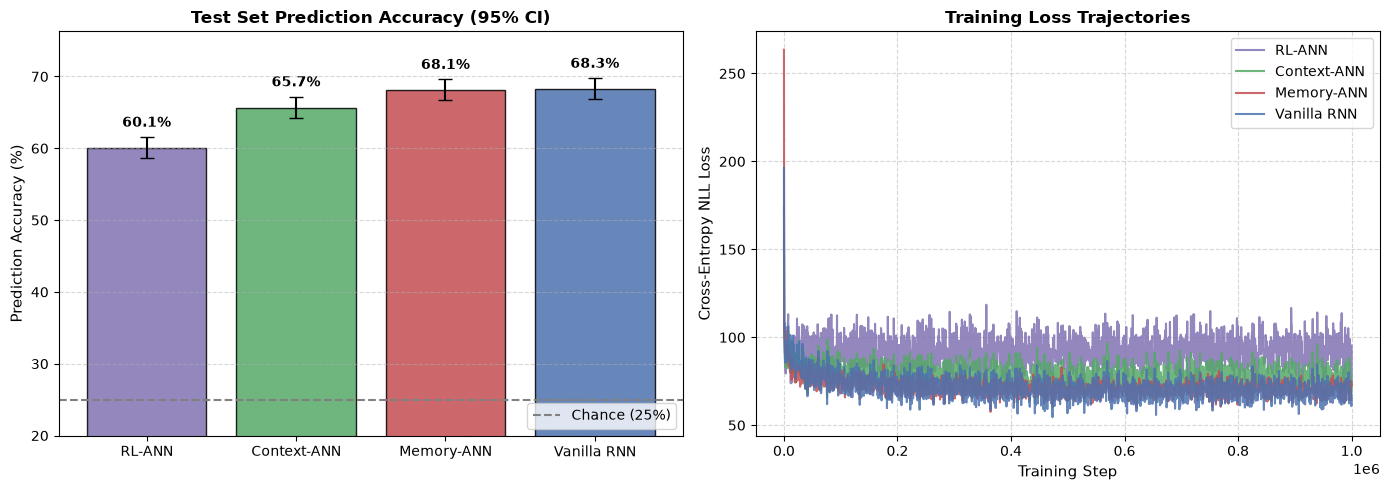

In [ ]:
# ── 8. Model Comparison: Performance Across the 4 Models ──────────────────────
# Comparison order: RL-ANN, Context-ANN, Memory-ANN, Vanilla RNN
comparison_order = ['RL-ANN', 'Context-ANN', 'Memory-ANN', 'Vanilla RNN']

# Filter models that have been fitted
models_to_compare = [m for m in comparison_order if m in all_model_results]

# Architecture descriptions
arch_descriptions = {
    'RL-ANN':      'BiRNN (o=False, s=False)',
    'Context-ANN': 'BiRNN (o=True, s=False)',
    'Memory-ANN':  'BiRNN (s=True, o=False, zero_values=True)',
    'Vanilla RNN': 'RNN (s=True, o=False)',
}

summary_rows = []
for name in models_to_compare:
  res = all_model_results[name]
  cfg = res['config']
  summary_rows.append({
      'Model Name': name,
      'Architecture': arch_descriptions.get(name, cfg.model_name),
      'Hidden Units': cfg.network_params.hidden_size,
      'Batch Size': cfg.batch_size,
      'Mean Pred %': f"{res['mean_pct']:.2f}%",
      'SE': f"±{res['sem_pct']:.2f}%",
      '95% CI': f"({res['ci_95_min']:.2f}%, {res['ci_95_max']:.2f}%)",
      '_mean_num': res['mean_pct'],
      '_sem_num': res['sem_pct'],
      '_ci_err': 1.96 * res['sem_pct'],
  })

summary_df = pd.DataFrame(summary_rows)
display_cols = ['Model Name', 'Architecture', 'Hidden Units', 'Batch Size', 'Mean Pred %', 'SE', '95% CI']

print("=" * 82)
print("  MODEL FIT COMPARISON TABLE (Held-out Test Prediction Percentage)")
print("=" * 82)
print(summary_df[display_cols].to_string(index=False))
print("=" * 82)

# ── Visualization ─────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Test Prediction Accuracy with 95% Confidence Intervals
model_names = summary_df['Model Name']
means = summary_df['_mean_num']
errors = summary_df['_ci_err']
palette = ['#8172b3', '#55a868', '#c44e52', '#4c72b0']

bars = ax1.bar(
    model_names, means, yerr=errors, capsize=5,
    color=palette[:len(model_names)], alpha=0.85, edgecolor='black'
)
ax1.axhline(25.0, color='gray', linestyle='--', linewidth=1.5, label='Chance (25%)')
ax1.set_ylabel('Prediction Accuracy (%)', fontsize=11)
ax1.set_title('Test Set Prediction Accuracy (95% CI)', fontsize=12, fontweight='bold')
ax1.set_ylim(20, max(float(means.max()) + 8, 75))
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for bar, mean, err in zip(bars, means, errors):
  ax1.text(
      bar.get_x() + bar.get_width() / 2, mean + err + 1.0,
      f"{mean:.1f}%", ha='center', va='bottom', fontsize=10, fontweight='bold'
  )
ax1.legend(loc='lower right')

# Subplot 2: Overlaid Training Loss Trajectories
for name, color in zip(models_to_compare, palette):
  res = all_model_results[name]
  ax2.plot(
      res['logged_steps'], res['train_loss_history'],
      label=f"{name}", color=color, alpha=0.85
  )

ax2.set_xlabel('Training Step', fontsize=11)
ax2.set_ylabel('Cross-Entropy NLL Loss', fontsize=11)
ax2.set_title('Training Loss Trajectories', fontsize=12, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()